In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
df = pd.read_csv('kc_house_data.csv')

print("5 data teratas")
print(df.head(), "\n")

print("Informasi dataset")
print(df.info(), "\n")

print("Deskripsi statistik dataset")
print(df.describe(),"\n")

5 data teratas
           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipcode 

In [3]:
df['date'] = pd.to_datetime(df['date'])
df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.month
df = df.drop(columns=['id', 'date'])
print(df.columns)

Index(['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',
       'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month'],
      dtype='str')


In [4]:
# missing values
print("Cek missing values")
print(df.isnull().sum())

Cek missing values
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
sale_year        0
sale_month       0
dtype: int64


Text(0, 0.5, 'Frekuensi')

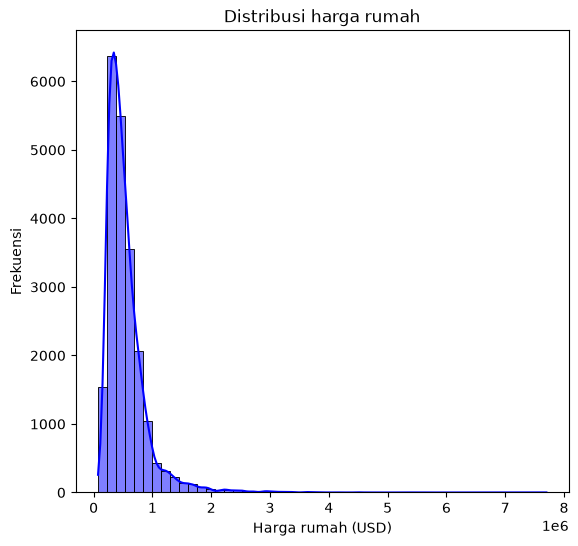

In [9]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(df['price'], kde=True, bins=50, color='blue')
plt.title("Distribusi harga rumah")
plt.xlabel('Harga rumah (USD)')
plt.ylabel('Frekuensi')

Text(0, 0.5, 'harga rumah (USD)')

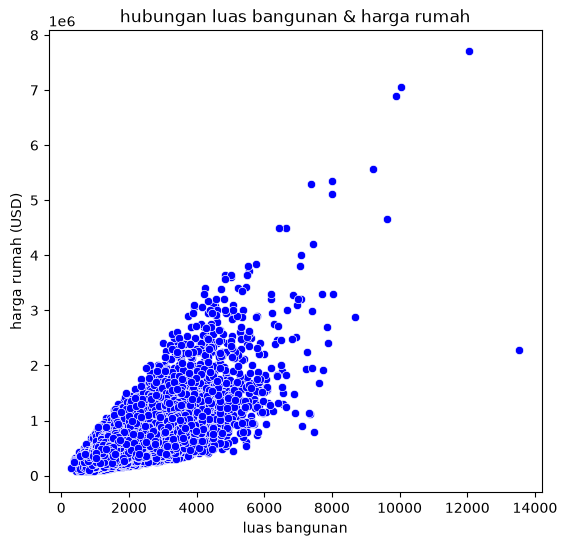

In [10]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(
    x='sqft_living', y='price', data=df, color='blue'
)
plt.title("hubungan luas bangunan & harga rumah")
plt.xlabel('luas bangunan')
plt.ylabel('harga rumah (USD)')

In [12]:
# feature selection
selected_features = [
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'floors',
    'grade',
    'sqft_above',
    'lat',
    'long',
]

X = df[selected_features]
y = df['price']

In [13]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# membuat model
model = LinearRegression()
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

# evaluasi model
print("HASIL EVALUASI MODEL")
print(f"R2 score train : {r2_train*100:.2f}%")
print(f"R2 score test : {r2_test*100:.2f}%\n")
print(f"RMSE train : {rmse_train*100:.2f}%")
print(f"RMSE test : {rmse_test*100:.2f}%")

HASIL EVALUASI MODEL
R2 score train : 61.90%
R2 score test : 62.17%

RMSE train : 22311390.71%
RMSE test : 23914750.23%


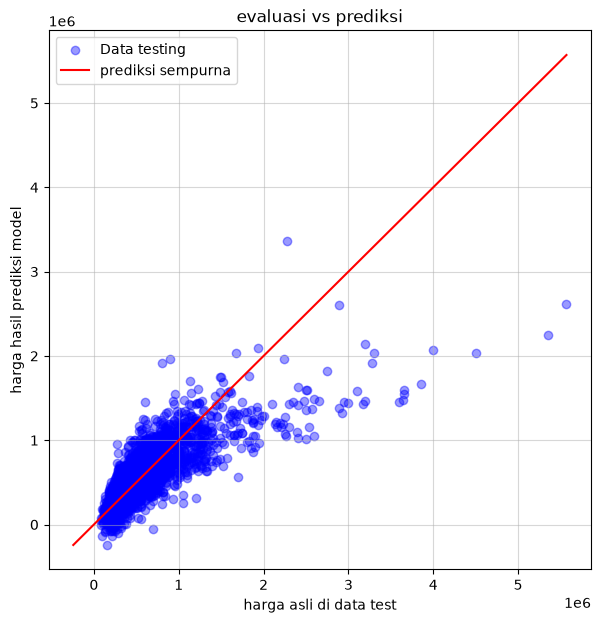

In [28]:
plt.figure(figsize=(7,7))
plt.scatter(
    y_test,
    y_pred_test,
    color='blue',
    label='Data testing',
    alpha=0.4
)

min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.min())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    label='prediksi sempurna',
)

plt.title("evaluasi vs prediksi")
plt.xlabel('harga asli di data test')
plt.ylabel('harga hasil prediksi model')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()